# [GSE150633](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE150633)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-10-12
> - Modified: 2025-04-26

# 1. Experimental Design

> Differential contribution to gene expression prediction of histone modifications at enhancers or promoters.
> - González-Ramírez M, Ballaré C, Mugianesi F, Beringer M, Santanach A, et al. (2021) Differential contribution to gene expression prediction of histone modifications at enhancers or promoters. PLOS Computational Biology 17(9): e1009368. https://doi.org/10.1371/journal.pcbi.1009368.
> - Mus musculus embryonic stem cells, E14Tg2A
> - ChIP-seq
> - mm10

| Marks | Function | Chromatin Status |
| - | - | - |
| **H3K4me3** | Promoter / TSS | Active |
| **H3K4me1** | Enhancer | Enhancer-associated / Poised |
| **H3K27ac** | Active enhancer / Promoter | Active |
| **H3K27me1** | Gene body; transcription-associated chromatin | Active / Transcription-associated |
| **H3K27me2** | Broad chromatin-associated modification; associated with non-active regulatory regions | Repressive / Inactive |
| **H3K27me3** | Polycomb-repressed promoters / domains | Repressed |
| **H3K36me3** | Gene body, especially transcribed regions | Transcriptional elongation |
| **H3K79me2** | Gene body; transcription-associated chromatin | Active / Transcriptional elongation |
| **H4K20me3** | Constitutive heterochromatin / repetitive regions | Repressed / Heterochromatic |
| **H2Bub** | Transcription-associated chromatin; gene activation and elongation | Active / Transcription-associated |
| **H3** | Total histone H3; normalization / nucleosome occupancy | Histone occupancy |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/chipseq_Mm_mESC_Histone_GSE150633/02_output"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [3]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

In [4]:
marks <- c(
    "H3K4me3", "H3K4me1", "H3K27ac", "H3K27me1", "H3K27me2", "H3K27me3", 
    "H3K36me3", "H3K79me2", "H4K20me3", "H2Bub", "H3")

## 1). narrowPeak Import

In [5]:
load_peaks <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE, 
    blacklist = NULL, format = "auto") {

    if (format == "auto") {
        if (grepl("\\.narrowPeak$", file)) {
            format <- "narrowPeak"
        } else if (grepl("\\.broadPeak$", file)) {
            format <- "broadPeak"
        } else if (grepl("\\.gappedPeak$", file)) {
            format <- "gappedPeak"
        } else {
            format <- "BED"
        }
    }

    gr <- rtracklayer::import(file, format = format)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY", "X", "Y"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist region (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [6]:
peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("^mESC_(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |>
    cat(sep = "\n")

H2Bub: mESC_H2Bub_peaks.narrowPeak
H3: mESC_H3_peaks.narrowPeak
H3K27ac: mESC_H3K27ac_peaks.narrowPeak
H3K27me1: mESC_H3K27me1_peaks.narrowPeak
H3K27me2: mESC_H3K27me2_peaks.narrowPeak
H3K27me3: mESC_H3K27me3_peaks.narrowPeak
H3K36me3: mESC_H3K36me3_peaks.narrowPeak
H3K4me1: mESC_H3K4me1_peaks.narrowPeak
H3K4me3: mESC_H3K4me3_peaks.narrowPeak
H3K79me2: mESC_H3K79me2_peaks.narrowPeak
H4K20me3: mESC_H4K20me3_peaks.narrowPeak


In [7]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file)

peaks_list <- peaks_list[marks]

peaks_list[1]

$H3K4me3
GRanges object with 59074 ranges and 6 metadata columns:
          seqnames            ranges strand |                   name     score
             <Rle>         <IRanges>  <Rle> |            <character> <numeric>
      [1]     chr1   3531473-3531988      * |   mESC_H3K4me3_peak_17       395
      [2]     chr1   3670496-3672626      * |   mESC_H3K4me3_peak_18      3425
      [3]     chr1   4085598-4086063      * |   mESC_H3K4me3_peak_19       145
      [4]     chr1   4491489-4493970      * |   mESC_H3K4me3_peak_20      1978
      [5]     chr1   4496467-4497843      * |   mESC_H3K4me3_peak_21       428
      ...      ...               ...    ... .                    ...       ...
  [59070]     chrY   1069708-1070215      * | mESC_H3K4me3_peak_61..       285
  [59071]     chrY   1243786-1246362      * | mESC_H3K4me3_peak_61..      2114
  [59072]     chrY   1253096-1254256      * | mESC_H3K4me3_peak_61..       156
  [59073]     chrY   6168140-6168404      * | mESC_H3K4me3_peak_6

## 2). bigwig Import

In [8]:
load_bigwig <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE, 
    blacklist = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY", "X", "Y"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [9]:
signals_files <- file.path(data_dir, "07_bigwig") |>
    list.files(pattern = "\\.(bigWig|bw)$", full.names = TRUE) |>
    set_names(~ sub("^mESC_(.*).bw$", "\\1", basename(.x)))

paste(names(signals_files), basename(signals_files), sep = ": ") |>
    cat(sep = "\n")

H2Bub: mESC_H2Bub.bw
H3: mESC_H3.bw
H3K27ac: mESC_H3K27ac.bw
H3K27me1: mESC_H3K27me1.bw
H3K27me2: mESC_H3K27me2.bw
H3K27me3: mESC_H3K27me3.bw
H3K36me3: mESC_H3K36me3.bw
H3K4me1: mESC_H3K4me1.bw
H3K4me3: mESC_H3K4me3.bw
H3K79me2: mESC_H3K79me2.bw
H4K20me3: mESC_H4K20me3.bw
Input: mESC_Input.bw


In [10]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file)

signals_list <- signals_list[c(marks, "Input")]

signals_list[1]

$H3K4me3
GRanges object with 22056339 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1         1-3000610      * |    0.0000
         [2]     chr1   3000611-3000670      * |    3.5823
         [3]     chr1   3000671-3000740      * |    0.0000
         [4]     chr1   3000741-3000800      * |    3.5823
         [5]     chr1   3000801-3001150      * |    0.0000
         ...      ...               ...    ... .       ...
  [22056335]     chrY 41155971-41155990      * |    3.5823
  [22056336]     chrY 41155991-41156350      * |    0.0000
  [22056337]     chrY 41156351-41156410      * |    3.5823
  [22056338]     chrY 41156411-41157710      * |    0.0000
  [22056339]     chrY 41157711-41157770      * |    3.5823
  -------
  seqinfo: 21 sequences from an unspecified genome


# 3. Quality Control

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Fragment Size Distribution

> - Single-end sequence

## 3). Fingerprints

> - Diaz, A., Nellore, A. & Song, J.S. CHANCE: comprehensive software for quality control and validation of ChIP-seq data. Genome Biol 13, R98 (2012). https://doi.org/10.1186/gb-2012-13-10-r98

In [11]:
# Cumulative Distribution Function
plot_df <- file.path(data_dir, "01_stats", "fingerprint.tsv") |>
    read.table(
        header = TRUE, sep = "\t", check.names = FALSE, comment.char = "#") |>
    pivot_longer(
        cols = everything(), names_to = "Sample", values_to = "Counts") |>
    separate_wider_delim(
        cols = Sample, names = c("Cell", "Marks"),
        delim = "_", cols_remove = FALSE) |>
    mutate(
        Marks = factor(Marks, levels = c(marks, "Input"))) |>
    arrange(Sample, Counts) |>
    group_by(Sample) |>
    mutate(
        cum_reads = cumsum(Counts),
        fraction_reads = cum_reads / last(cum_reads),
        fraction_bins = row_number() / n()) |>
    ungroup()

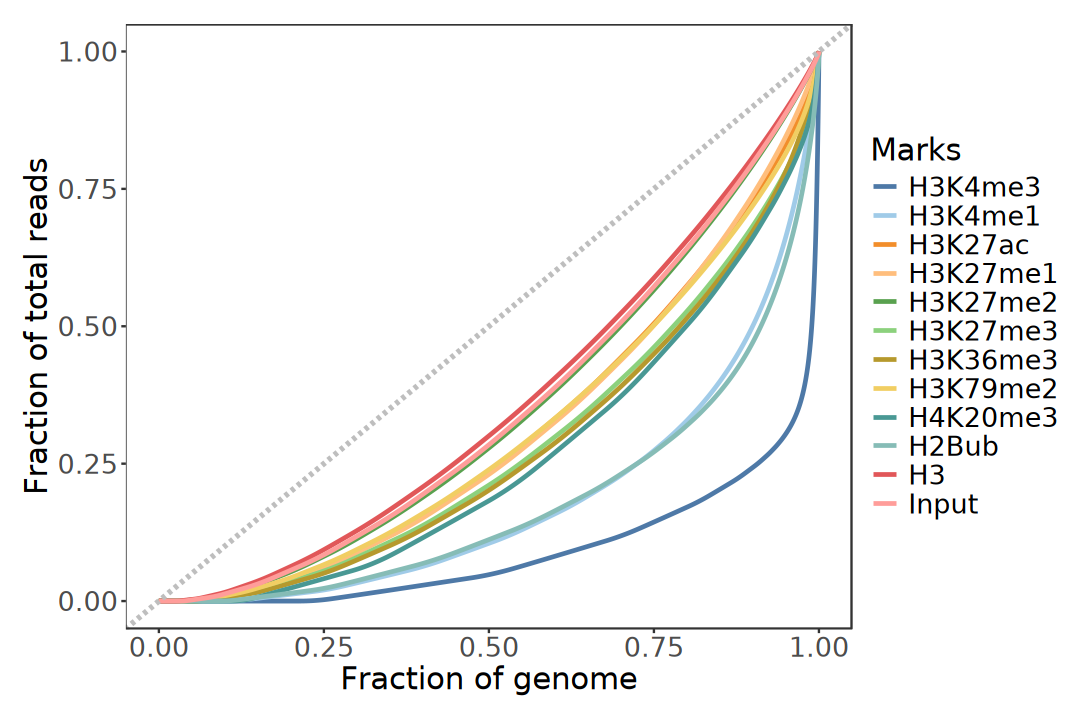

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = fraction_bins, y = fraction_reads)) +
    geom_line(aes(color = Marks), linewidth = 1) +
    geom_abline(
        slope = 1, intercept = 0, color = "gray", 
        linetype = "dashed", linewidth = 1.2) +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    labs(x = "Fraction of genome", y = "Fraction of total reads") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). TSS Enrichment Score

In [13]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    nbins <- length(profile)
    flank_bins <- 100 / bs

    background <- c(
        profile[1:flank_bins], 
        profile[(nbins - flank_bins + 1):nbins]) |> mean()

    norm_profile <- profile / background

    center_bin <- floor(nbins / 2)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = seq(-2000, 1990, by = bs),
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")"))
}

In [14]:
matrix_files <- file.path(data_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

profiles_list <- imap(matrix_files, compute_tss_score, verbose = TRUE)

mESC_H2Bub TSS Enrichment Score: 0.45

mESC_H3 TSS Enrichment Score: 0.59

mESC_H3K27ac TSS Enrichment Score: 1.42

mESC_H3K27me1 TSS Enrichment Score: 0.75

mESC_H3K27me2 TSS Enrichment Score: 0.65

mESC_H3K27me3 TSS Enrichment Score: 0.92

mESC_H3K36me3 TSS Enrichment Score: 0.45

mESC_H3K4me1 TSS Enrichment Score: 0.8

mESC_H3K4me3 TSS Enrichment Score: 9.55

mESC_H3K79me2 TSS Enrichment Score: 0.42

mESC_H4K20me3 TSS Enrichment Score: 0.89

mESC_Input TSS Enrichment Score: 1.09



In [15]:
profile_df <- do.call(rbind, profiles_list) |>
    separate(Sample, into = c("Cell", "Marks"), sep = "_", remove = FALSE) |>
    mutate(Marks = factor(Marks, levels = c(marks, "Input"))) |>
    arrange(Marks) |>
    mutate(Label = forcats::fct_inorder(as.character(Label)))

,Position,Signal,Sample,Cell,Marks,TSS_Score,Label
,<dbl>,<dbl>,<chr>,<chr>,<fct>,<dbl>,<fct>
mESC_H3K4me3.V1,-2000,4.184597,mESC_H3K4me3,mESC,H3K4me3,9.552137,mESC_H3K4me3 (Score: 9.55)
mESC_H3K4me3.V2,-1990,4.199132,mESC_H3K4me3,mESC,H3K4me3,9.552137,mESC_H3K4me3 (Score: 9.55)
mESC_H3K4me3.V3,-1980,4.215578,mESC_H3K4me3,mESC,H3K4me3,9.552137,mESC_H3K4me3 (Score: 9.55)
mESC_H3K4me3.V4,-1970,4.215660,mESC_H3K4me3,mESC,H3K4me3,9.552137,mESC_H3K4me3 (Score: 9.55)
mESC_H3K4me3.V5,-1960,4.222799,mESC_H3K4me3,mESC,H3K4me3,9.552137,mESC_H3K4me3 (Score: 9.55)
mESC_H3K4me3.V6,-1950,4.241136,mESC_H3K4me3,mESC,H3K4me3,9.552137,mESC_H3K4me3 (Score: 9.55)


In [16]:
# Automatically generate a corresponding marks color for every label.
unique_labels <- levels(profile_df$Label)
associated_antibodies <- sub(
    "^mESC_(.*)\\s+\\(Score:.*\\)", "\\1", unique_labels)
associated_antibodies <- factor(
    associated_antibodies, levels = c(marks, "Input"))

marks_colors <- ggthemes::tableau_color_pal(
    palette = "Tableau 20")(nlevels(associated_antibodies))

label_color_mapping <- marks_colors[as.numeric(associated_antibodies)]
names(label_color_mapping) <- unique_labels

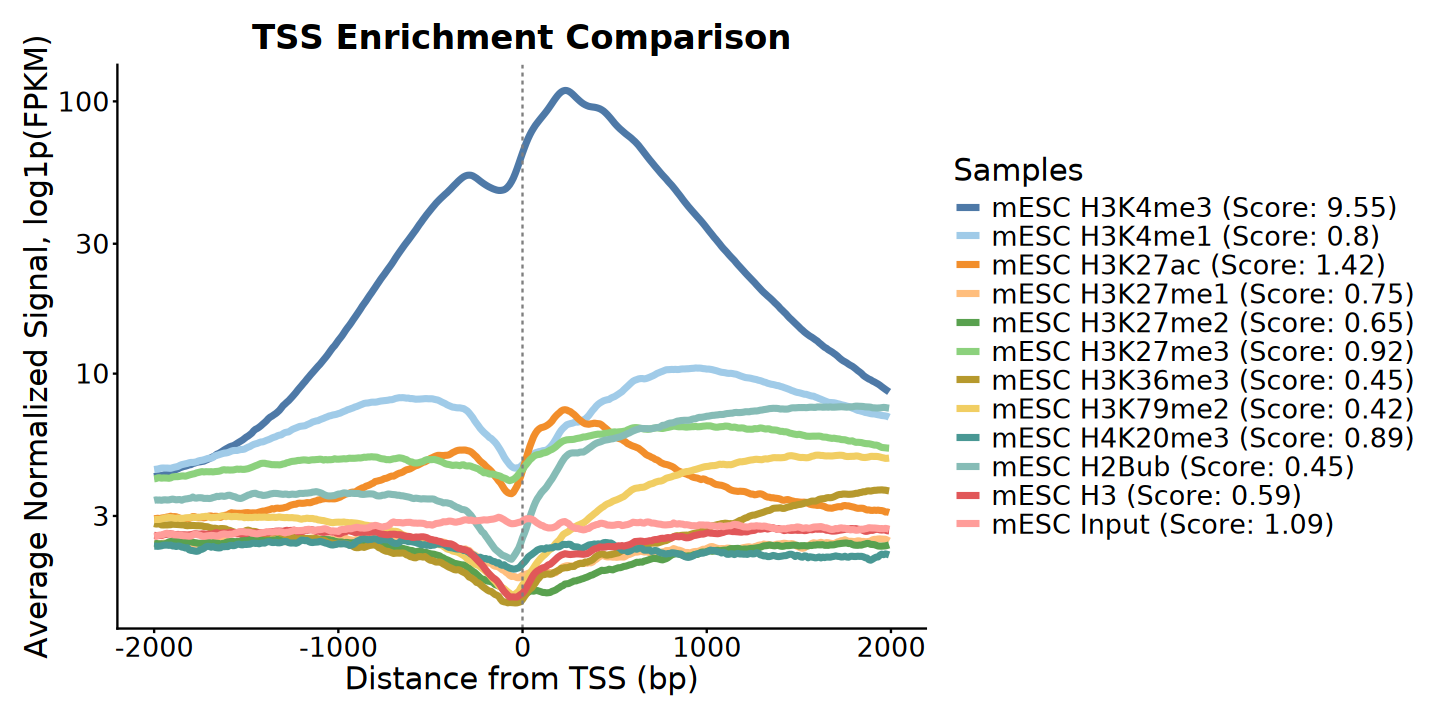

In [17]:
options(repr.plot.width = 12, repr.plot.height = 6)

ggplot(profile_df, aes(x = Position, y = Signal)) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_y_log10() +
    scale_color_manual(
        values = label_color_mapping, labels = function(x) gsub("_", " ", x)) +
    guides(color = guide_legend(ncol = 1)) +
    labs(
        title = "TSS Enrichment Comparison",
        color = "Samples",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Peak Width

In [18]:
peaks_qc <- map_dfr(names(peaks_list), function(mark) {
    peak <- peaks_list[[mark]]
    tibble(
        mark = mark, number_peak = length(peak),
        median_width = median(width(peak)),
        mean_width = mean(width(peak)),
        min_width = min(width(peak)),
        max_width = max(width(peak)),
        genome_coverage = sum(width(peak))
    )
}) |> mutate(mark = factor(mark, levels = marks))

peaks_qc

Warning message in min(width(peak)):
“no non-missing arguments to min; returning Inf”
Warning message in max(width(peak)):
“no non-missing arguments to max; returning -Inf”
Warning message in min(width(peak)):
“no non-missing arguments to min; returning Inf”
Warning message in max(width(peak)):
“no non-missing arguments to max; returning -Inf”


mark,number_peak,median_width,mean_width,min_width,max_width,genome_coverage
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
H3K4me3,59074,611,936.1304,186,12581,55300965
H3K4me1,152630,467,678.2615,206,18260,103523056
H3K27ac,19198,322,410.5185,191,4712,7881134
H3K27me1,5617,303,345.5462,243,1458,1940933
H3K27me2,0,NA,NaN,Inf,-Inf,0
H3K27me3,33244,412,838.0415,216,23937,27859850
H3K36me3,66021,365,546.6510,208,14241,36090447
H3K79me2,27379,327,502.6067,183,11322,13760870
H4K20me3,36558,322,500.6879,174,8867,18304148


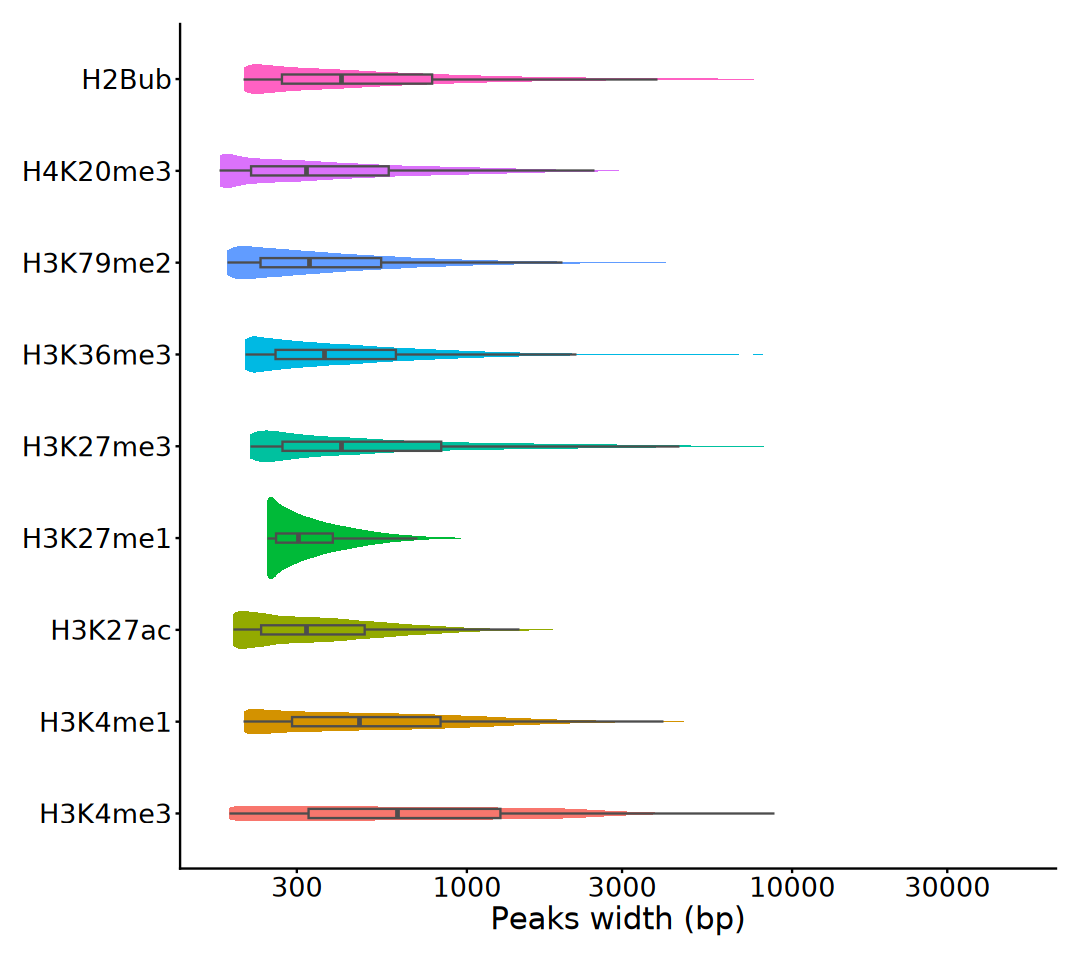

In [19]:
options(repr.plot.width = 9, repr.plot.height = 8)

map_dfr(names(peaks_list), function(mark) {
    tibble(mark = mark, width = width(peaks_list[[mark]]))
}) |> mutate(mark = factor(mark, levels = marks)) |>
ggplot(aes(x = mark, y = width, fill = mark)) +
    geom_violin(trim = TRUE, color = NA) +
    geom_boxplot(width = 0.1, color = "grey30", outliers = FALSE) +
    scale_y_log10() +
    coord_flip() +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    labs(x = NULL, y = "Peaks width (bp)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [20]:
genome_bins <- seqinfo(genome) |>
    keepStandardChromosomes() |>
    dropSeqlevels(c("chrX", "chrY", "chrM")) |>
    seqlengths() |>
    tileGenome(tilewidth = 1e5, cut.last.tile.in.chrom = TRUE)

In [21]:
# ~ 10 minutes, 32G memory
bin_means_df <- purrr::map(signals_files, function(file) {
    import(BigWigFile(file), which = genome_bins, as = "NumericList") |>
        mean(na.rm = TRUE) |>
        tidyr::replace_na(0)
}) |> as.data.frame()

In [22]:
bin_means_df <- as.data.frame(genome_bins) |>
    cbind(bin_means_df[marks]) |>
    filter(apply(pick(all_of(marks)), 1, var) > 0)

In [23]:
cor_mat <- cor(bin_means_df[marks], method = "spearman")

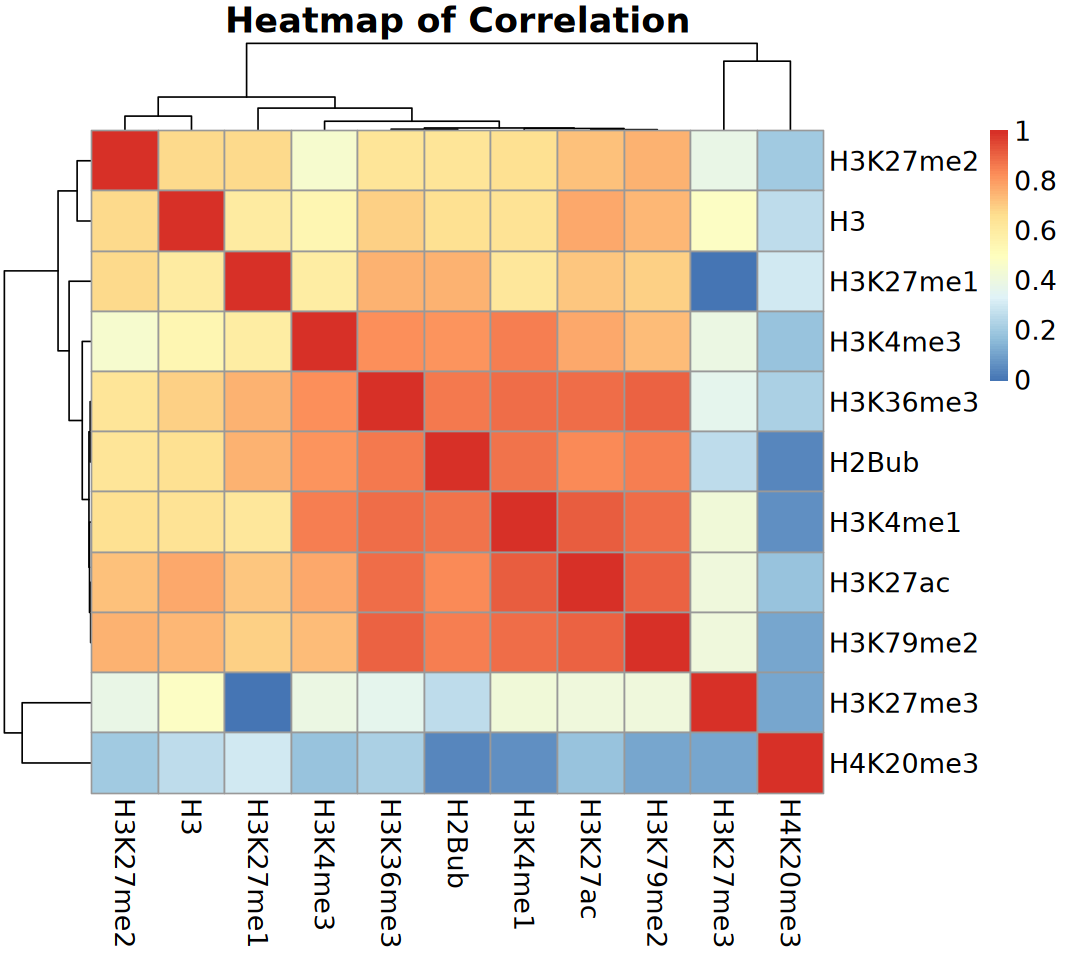

In [24]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation", 
    clustering_distance_cols = "correlation", 
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = TRUE, show_rownames = TRUE)

In [25]:
pca_df <- bin_means_df[, marks] |> t() |>
    prcomp(center = TRUE, scale. = TRUE)

per_var <- round(pca_df$sdev^2 / sum(pca_df$sdev^2) * 100, 2)

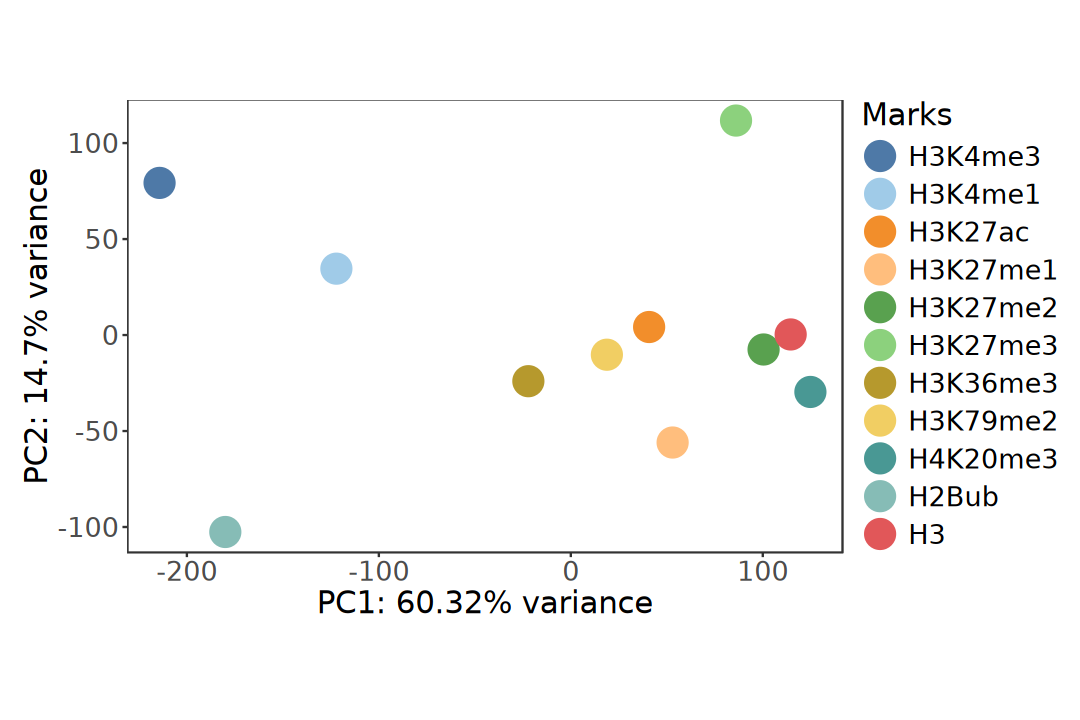

In [26]:
options(repr.plot.width = 9, repr.plot.height = 6)

pca_df$x |> as.data.frame() |> 
    rownames_to_column(var = "Marks") |>
    mutate(Marks = factor(Marks, levels = marks)) |>
ggplot(aes(PC1, PC2)) +
    geom_point(aes(color = Marks), size = 8) +
    coord_fixed() +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Metagene Profile

In [27]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

In [28]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [29]:
# ~ 16 minutes
gene_mat_list <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    mean_mode = "w0", extend = 2000, w = 50, smooth = FALSE, 
    target_ratio = 0.4, background = NA)

In [30]:
base_cols <- ggthemes::tableau_color_pal("Tableau 20")(
    length(gene_mat_list)) |> 
    setNames(names(gene_mat_list)
)

plot_cols <- lapply(names(gene_mat_list), function(mark) {
    max_signal <- gene_mat_list[[mark]] |> 
        abs() |> quantile(0.99, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_signal / 2, max_signal), 
        c("#FFFFFF", base_cols[[mark]], "#03045E"))
})

names(plot_cols) <- names(gene_mat_list)

In [31]:
lgd_list <- lapply(names(plot_cols), function(mark) {
    Legend(
        col_fun = plot_cols[[mark]], title = mark, 
        title_gp = gpar(fontsize = 12, fontface = "bold"),
        labels_gp = gpar(fontsize = 10), grid_width = unit(0.4, "cm"))
})

lgd_col1 <- packLegend(list = lgd_list[1:6], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[7:12], direction = "vertical")
packed_lgds <- packLegend(
    lgd_col1, lgd_col2, direction = "horizontal", 
    gap = unit(0.8, "cm"))

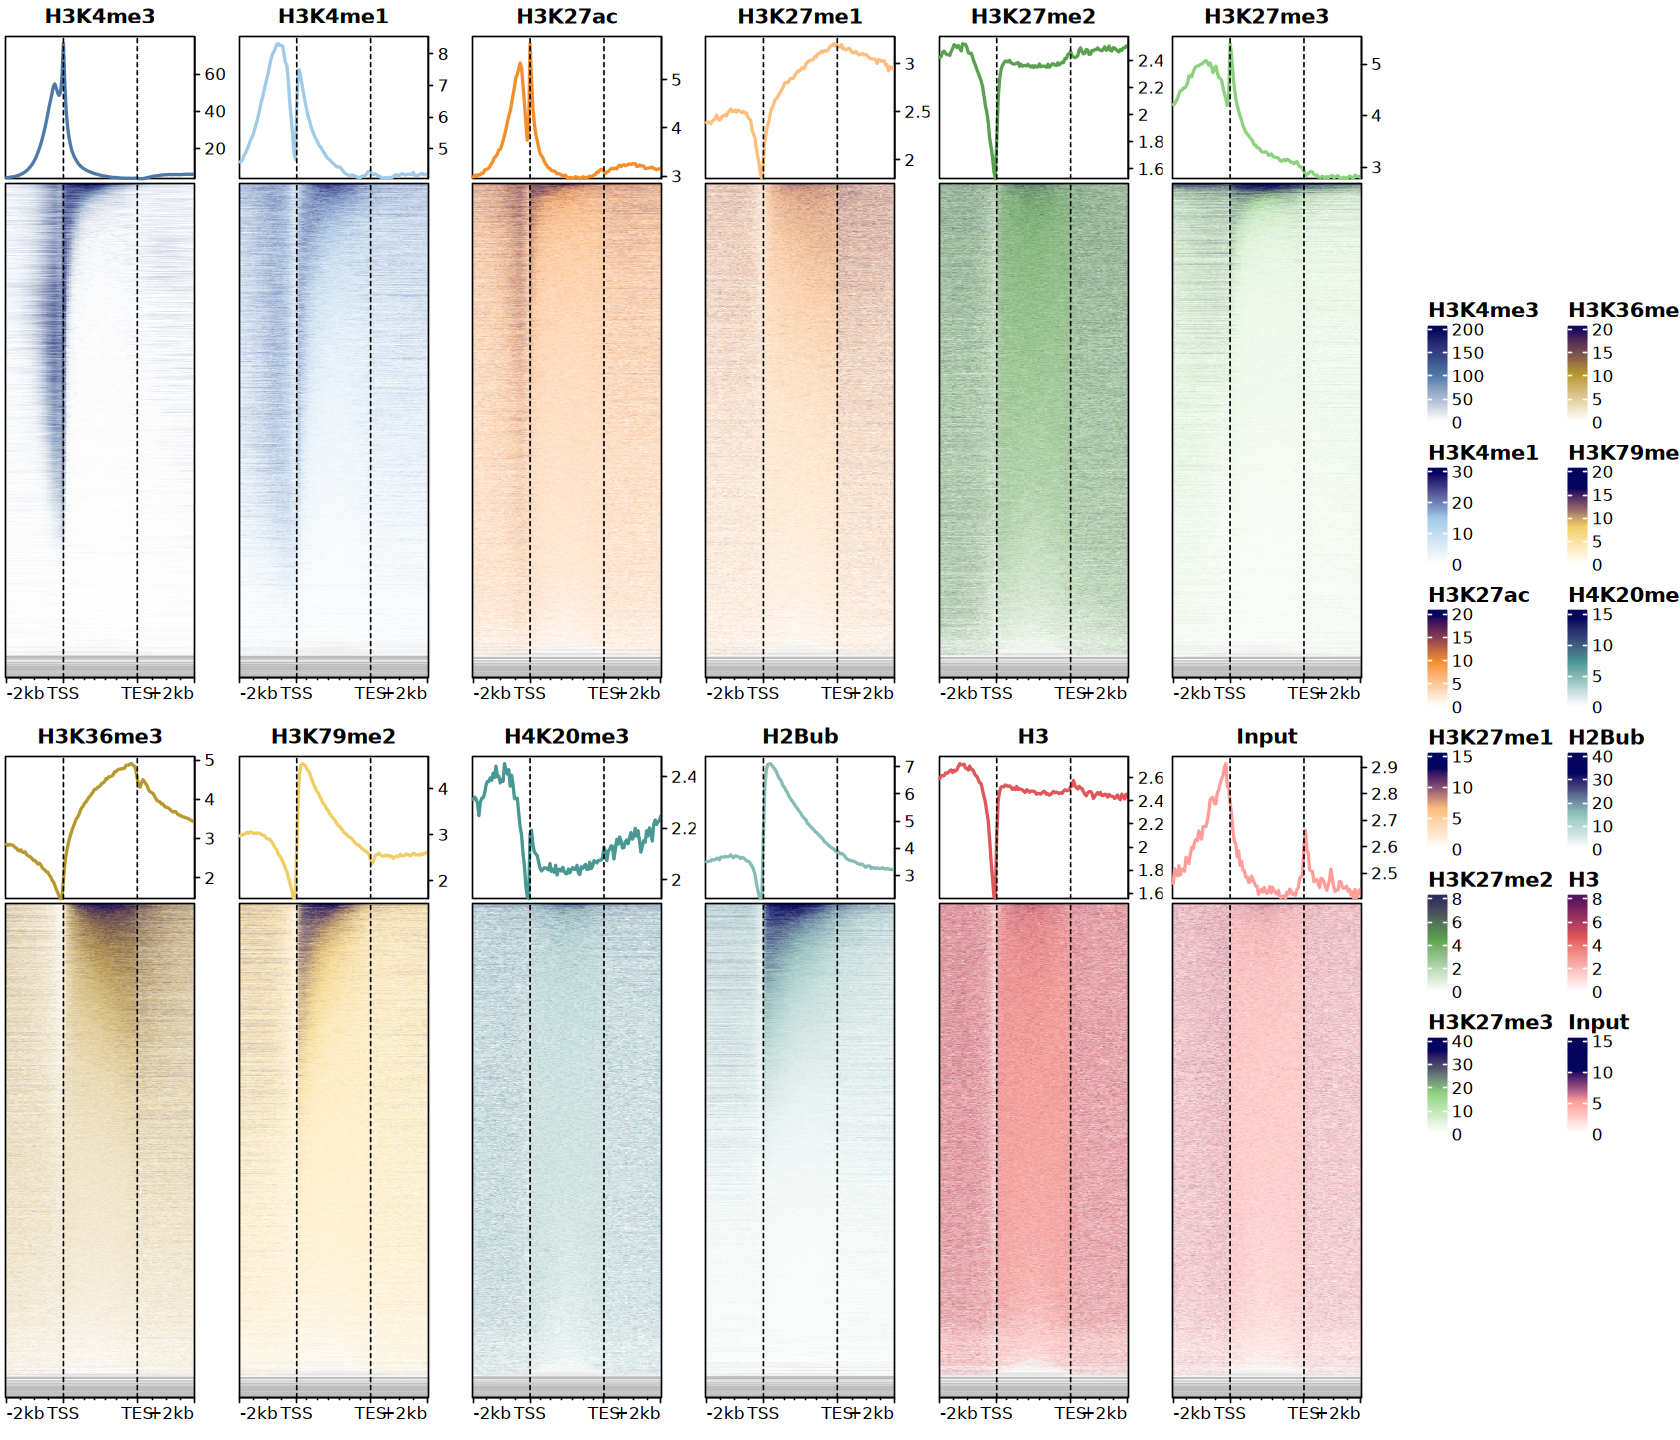

In [32]:
# ==============================================================================
# ⚠️ WARNING / IMPORTANT NOTE:
# With the current settings, the row order (gene/peak order) across different 
# heatmaps is INCONSISTENT. Each heatmap calculates its own hierarchical 
# clustering independently based on its input matrix. If you want to visually 
# compare rows across different groups, you must enforce a unified row order 
# by setting 'cluster_rows = FALSE' and providing a fixed 'row_order'.
# ==============================================================================

options(repr.plot.width = 14, repr.plot.height = 12)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(
    layout = grid.layout(2, 7, widths = c(rep(1, 6), 1.2))))

for (idx in seq_along(gene_mat_list)) {
    mark <- names(gene_mat_list)[idx]

    # Enter the designated grid slot (viewport)
    row_idx <- if (idx <= 6) 1 else 2
    col_idx <- if (idx <= 6) idx else idx - 6
    pushViewport(viewport(
        layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        gene_mat_list[[idx]], 
        name = mark, 
        column_title = mark, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        axis_name_gp = gpar(fontsize = 10), 
        width = unit(4, "cm"), 
        show_row_names = FALSE, 
        col = plot_cols[[mark]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = base_cols[mark]), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), show_legend = FALSE), 
        show_heatmap_legend = FALSE, 
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 7))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

In [33]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40)
)

profiles_df <- purrr::imap_dfr(
    gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Marks = .y,
        Signal = colMeans(.x, na.rm = TRUE))) |> 
    mutate(Marks = factor(Marks, levels = c(marks, "Input")))

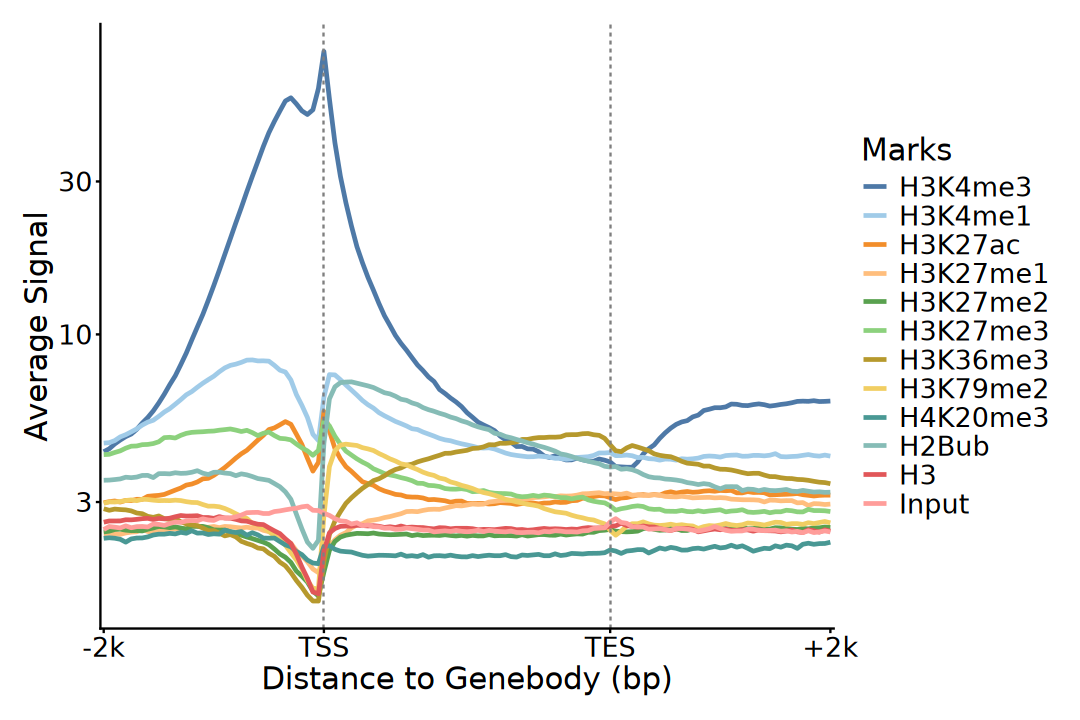

In [34]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Signal)) +
    geom_line(aes(color = Marks, group = Marks), linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) +
    scale_y_log10() +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    labs(x = "Distance to Genebody (bp)", y = "Average Signal") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "right",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 5. Peak Annotation

In [35]:
suppressPackageStartupMessages(library(ChIPseeker))

In [36]:
peaks_list[c("H3K27me2", "H3")] <- NULL

In [37]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>.”


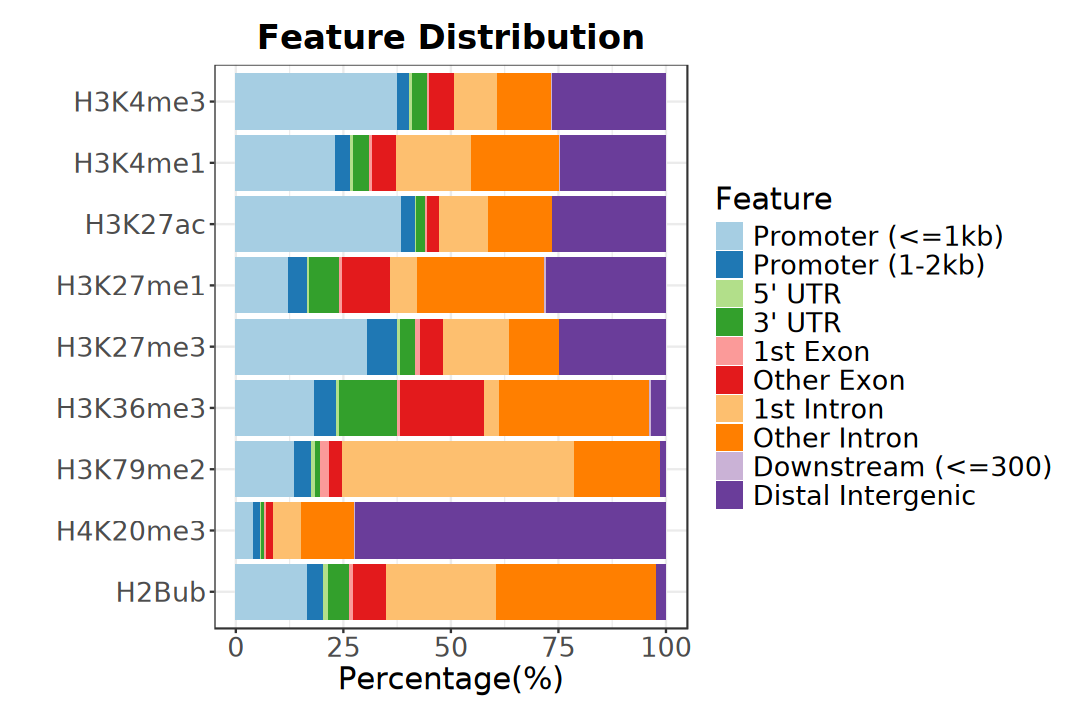

In [38]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

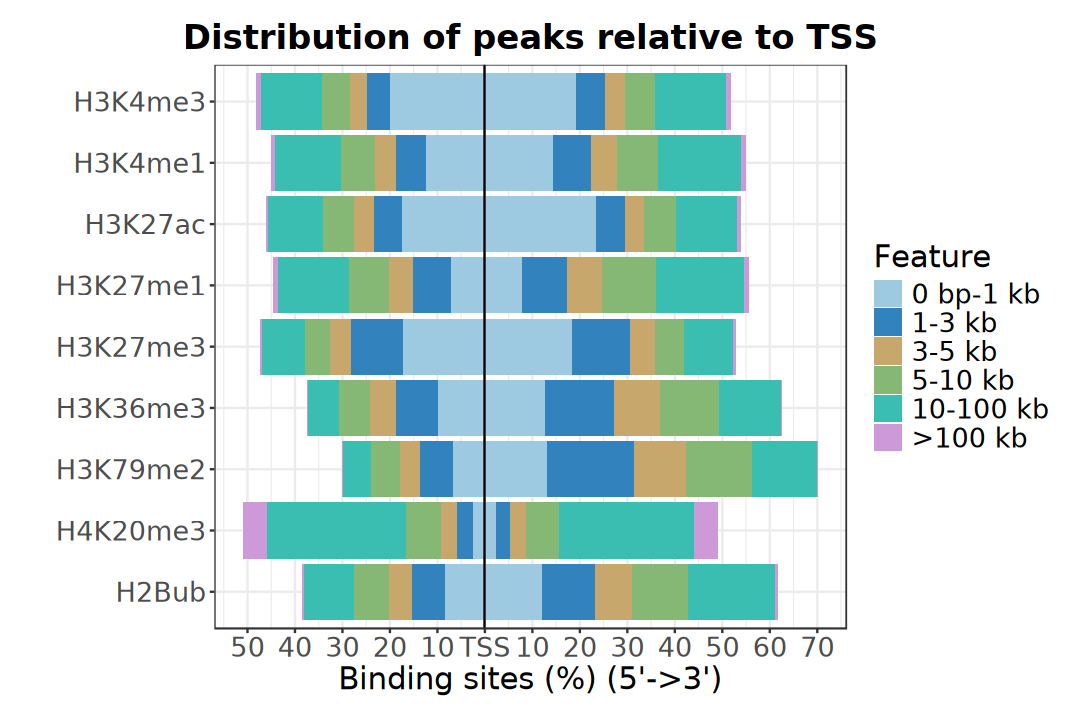

In [39]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDistToTSS(
    peaks_anno_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 6. IGV Snapshot

In [40]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [41]:
# Hoxa
genome = "mm10"
target_region <- "chr6:52150000-52230000"

In [42]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr6:52150000-52230000,chr6,52150000,52230000


In [43]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [44]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [45]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 14, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [46]:
base_cols <- ggthemes::tableau_color_pal("Tableau 20")(
    length(gene_mat_list)) |> 
    setNames(names(gene_mat_list)
)

In [47]:
signal_tracks <- purrr::imap(
    signals_list, ~ Gviz::DataTrack(
        range = .x, name = .y, type = "histogram",
        chromosome = target_region$chr, genome = genome,
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = base_cols[.y],
        fill.histogram = base_cols[.y]
    )
)

In [48]:
grtrack <- GeneRegionTrack(
    txdb, genome = genome, chromosome = target_region$chr, 
    start = target_region$start, end = target_region$end,
    transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 20, 
    cex.title = 1, fontsize.group = 16, rotation.title = 0,
    name = "Gene", col = "grey", fill = "orange", 
    fontcolor.group = "black", stacking = "squish")

gene_info <- filter(gtf, type == "gene")

ranges(grtrack)$symbol <- gene_info$gene_name[
    match(ranges(grtrack)$gene, gene_info$gene_id)]

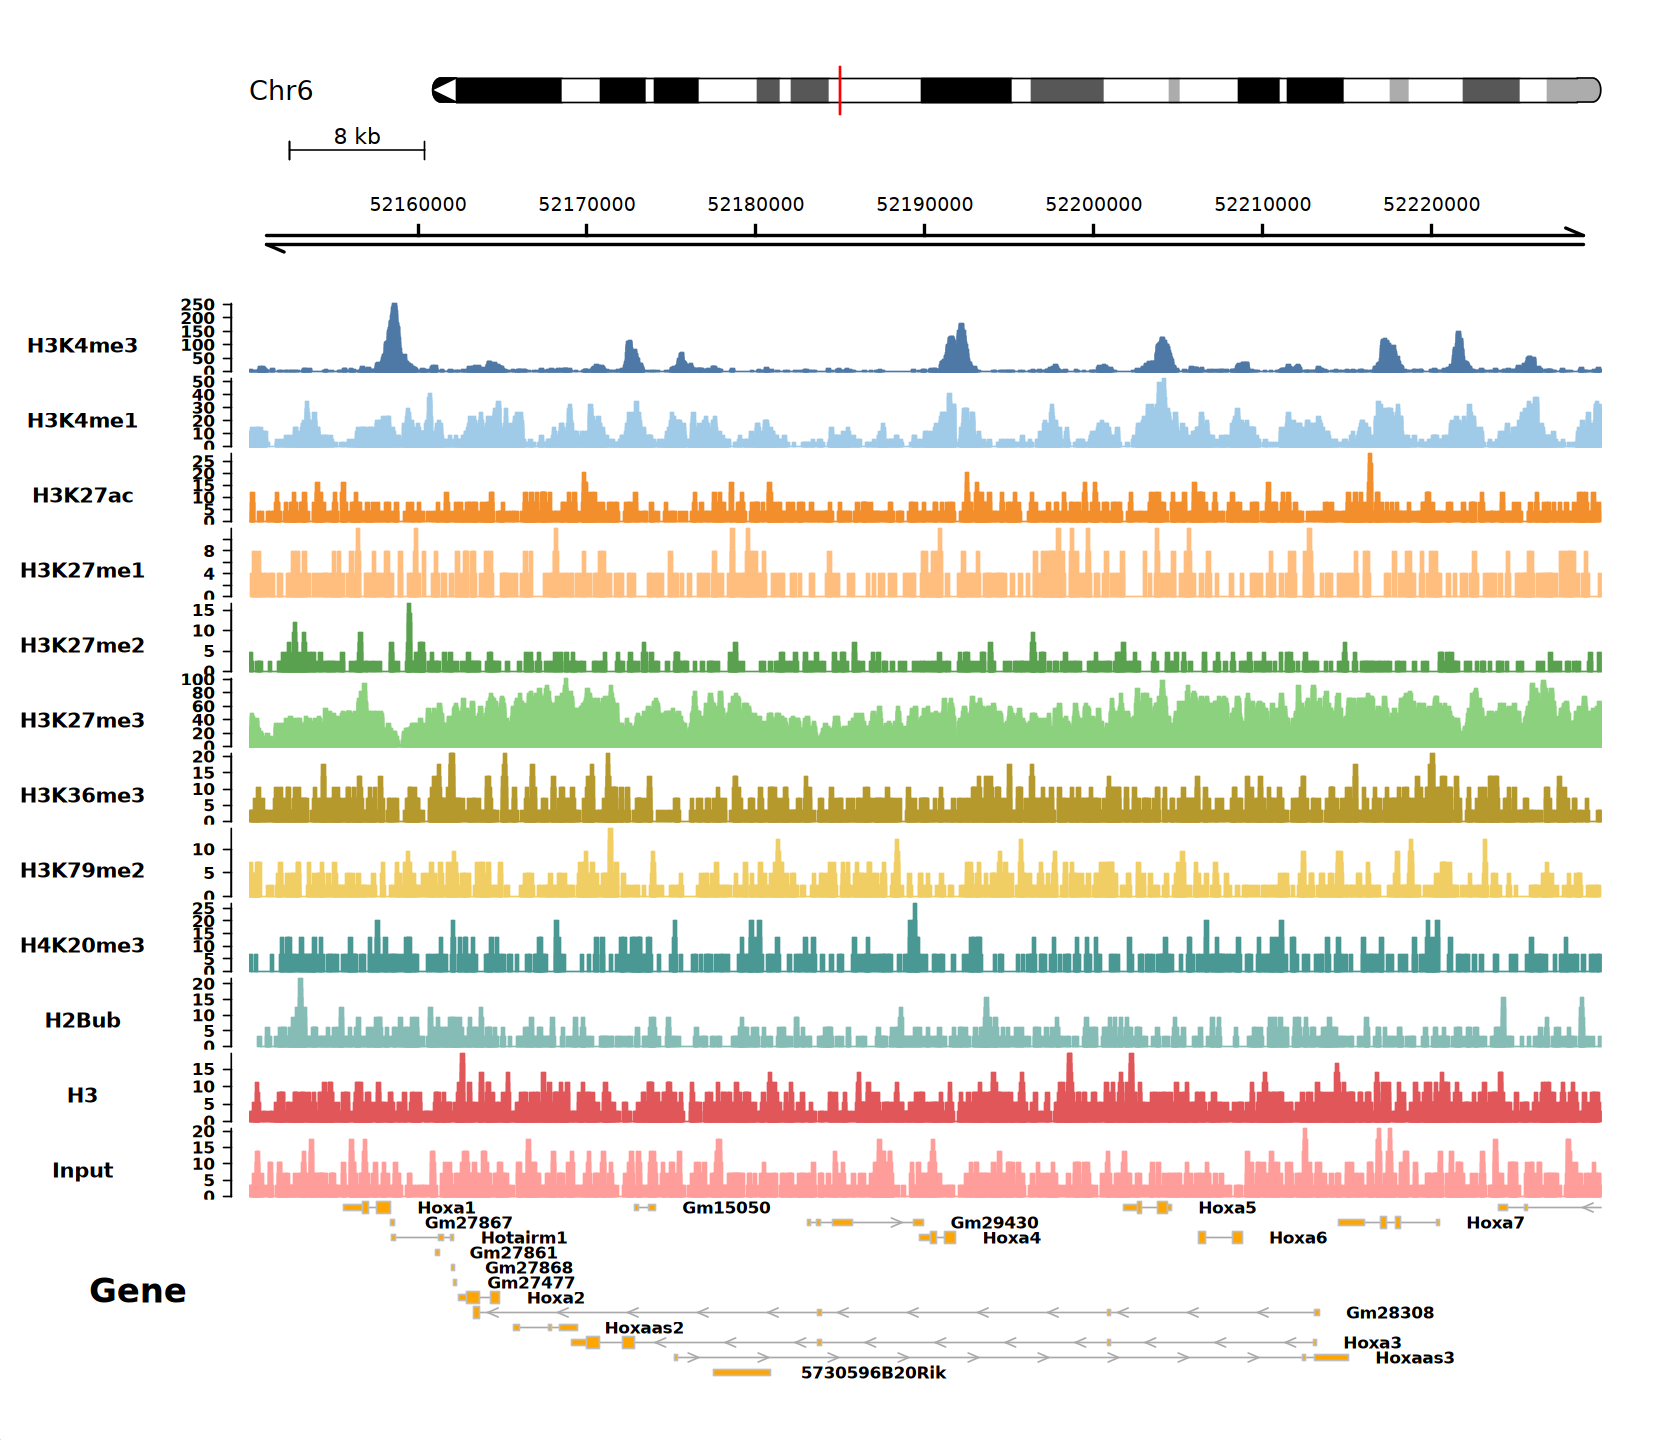

In [49]:
options(repr.plot.width = 14, repr.plot.height = 12)

plotTracks(
    trackList = c(plot_list, signal_tracks, grtrack), 
    chromosome = target_region$chr, 
    from = target_region$start, 
    to = target_region$end, 
    background.title = "white", 
    col.title = "black", 
    col.axis = "black", 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list)), 6), 
    reverseStrand = FALSE, 
    rotation.title = 0, 
    title.width = 1, 
    just.group = "right", 
    extend.left = 0, 
    margin = 20
)

# * Reference